# 02. Calendar and reviews EDA

The calendar and reviews files are where the demand-responsive signal has to
come from. The listings table has no profile views and no booking requests, so
the hypothesis depends on what can be reconstructed here: how booked out a
listing is, and how recently and how fast it is being reviewed.

Four constraints shape this notebook:

- **The calendar price columns are never read.** In this download the calendar
  has no price column at all, which is asserted below rather than assumed.
  Only the availability flag and the date are used. A calendar price would
  echo the target.
- Only the needed columns are read, with compact dtypes. The review text is
  never loaded, so it cannot reach any output.
- Every window is measured from the **snapshot date** in `last_scraped`, never
  from today.
- Nothing here is saved as a feature. Notebook 03 builds the aggregates; this
  notebook decides whether they are worth building.

Sections:

0. Setup
1. Calendar integrity and overall availability
2. Occupancy proxies over 30, 60, 90 and 365 days
3. Weekend against weekday
4. Dormant and fully open listings
5. Reviews over time and per listing
6. Review recency at the snapshot date
7. Relationship checks against log price
8. Recomputed review counts against the listings column
9. What these proxies can and cannot mean

## 0. Setup

The snapshot date is read from the listings table, which is the single
authority for it. The calendar and reviews files are read with `usecols` so
the 276 MB and 230 MB downloads never land in memory in full, and the review
`comments` column is never named anywhere.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_DATA_DIR, REPORTS_DIR  # noqa: E402
from src.preprocessing.target import parse_price  # noqa: E402

FIGURE_DIR = REPORTS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9.0, 5.0)
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"


def resolve_raw(stem: str) -> Path:
    """Return the raw file for a stem, accepting .csv or .csv.gz."""
    for suffix in (".csv", ".csv.gz"):
        candidate = RAW_DATA_DIR / f"{stem}{suffix}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"no {stem}.csv or {stem}.csv.gz in the raw data folder")


def save_figure(fig, name: str) -> None:
    """Write a figure under reports/figures and report the relative path."""
    fig.savefig(FIGURE_DIR / f"{name}.png")
    print(f"saved reports/figures/{name}.png")


# Listings: only the id, the price and the columns this notebook cross-checks.
LISTING_COLUMNS = [
    "id",
    "last_scraped",
    "price",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "room_type",
]
listings = pd.read_csv(resolve_raw("listings"), usecols=LISTING_COLUMNS)

snapshot_values = sorted(listings["last_scraped"].dropna().unique())
assert len(snapshot_values) == 1, f"last_scraped is not single valued: {snapshot_values}"
SNAPSHOT_DATE = pd.Timestamp(snapshot_values[0])

listings["price_num"] = parse_price(listings["price"])
listings["log_price"] = np.log1p(listings["price_num"].where(listings["price_num"] > 0))

print(f"snapshot date  : {SNAPSHOT_DATE.date()}")
print(f"listings       : {len(listings):,}")
print(f"priced         : {int(listings['price_num'].gt(0).sum()):,}")
print(f"calendar file  : {resolve_raw('calendar').name}")
print(f"reviews file   : {resolve_raw('reviews').name}")

snapshot date  : 2026-09-17
listings       : 20,833
priced         : 17,721
calendar file  : calendar.csv
reviews file   : reviews.csv


## 1. Calendar integrity and overall availability

The header is checked before anything is read, so the no-price rule is
enforced rather than trusted. Then: one row per listing and date, 365 days per
listing, and the overall split between available and unavailable.

In [2]:
FORBIDDEN_CALENDAR_COLUMNS = {"price", "adjusted_price"}

calendar_header = pd.read_csv(resolve_raw("calendar"), nrows=0).columns.tolist()
print(f"calendar columns in this download: {calendar_header}")
found_forbidden = FORBIDDEN_CALENDAR_COLUMNS.intersection(calendar_header)
print(f"price-like columns present       : {sorted(found_forbidden) or 'none'}")
print("  -> only listing_id, date and available are read either way")

CALENDAR_COLUMNS = ["listing_id", "date", "available"]
calendar = pd.read_csv(
    resolve_raw("calendar"),
    usecols=CALENDAR_COLUMNS,
    dtype={"listing_id": "int64", "available": "category"},
    parse_dates=["date"],
)
assert not FORBIDDEN_CALENDAR_COLUMNS.intersection(calendar.columns), "price column read"

print(f"\ncalendar rows      : {len(calendar):,}")
print(f"unique listings    : {calendar['listing_id'].nunique():,}")
print(f"date range         : {calendar['date'].min().date()} to "
      f"{calendar['date'].max().date()}")
print(f"starts at snapshot : {calendar['date'].min() == SNAPSHOT_DATE}")
print(f"duplicate (id,date): {int(calendar.duplicated(['listing_id', 'date']).sum()):,}")

rows_per_listing = calendar.groupby("listing_id").size()
print(f"\nrows per listing: min={rows_per_listing.min()}, "
      f"max={rows_per_listing.max()}, "
      f"all equal={rows_per_listing.nunique() == 1}")

print(f"\navailable flag values: {calendar['available'].value_counts().to_dict()}")
unavailable_share = (calendar["available"] == "f").mean()
print(f"overall share of listing-days unavailable : {unavailable_share:.4f}")
print(f"overall share of listing-days available   : {1 - unavailable_share:.4f}")

# Compact working columns: a day offset from the snapshot and a boolean flag.
calendar["unavailable"] = (calendar["available"] == "f").to_numpy()
calendar["day_offset"] = (calendar["date"] - SNAPSHOT_DATE).dt.days.astype("int16")
calendar = calendar.drop(columns=["available"])
print(f"\nday_offset range: {calendar['day_offset'].min()} to "
      f"{calendar['day_offset'].max()}")
print(f"memory held by the calendar frame: "
      f"{calendar.memory_usage(deep=True).sum() / 1e6:.0f} MB")

calendar columns in this download: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
price-like columns present       : none
  -> only listing_id, date and available are read either way



calendar rows      : 7,604,045
unique listings    : 20,833
date range         : 2026-09-17 to 2027-09-16
starts at snapshot : True


duplicate (id,date): 0

rows per listing: min=365, max=365, all equal=True

available flag values: {'f': 3958059, 't': 3645986}
overall share of listing-days unavailable : 0.5205
overall share of listing-days available   : 0.4795



day_offset range: 0 to 364
memory held by the calendar frame: 144 MB


## 2. Occupancy proxies over 30, 60, 90 and 365 days

`occ_N` is the share of the next N days, counted from the snapshot date, that
are marked unavailable. Higher means more booked out, or more blocked by the
host. Section 9 is explicit that the two cannot be separated.

The listings table ships its own `availability_N` columns, which count
**available** days. If the calendar and the listings table describe the same
snapshot then `occ_N` should equal `1 - availability_N / N`, so that identity
is checked as a cross-file integrity test.

occupancy proxy distributions (share of days unavailable)
           occ_30      occ_60      occ_90     occ_365
count  20833.0000  20833.0000  20833.0000  20833.0000
mean       0.5850      0.5300      0.4929      0.5205
std        0.3511      0.3586      0.3596      0.3424
min        0.0000      0.0000      0.0000      0.0000
10%        0.0333      0.0167      0.0111      0.0384
25%        0.2667      0.2000      0.1556      0.2027
50%        0.6333      0.5333      0.4556      0.5397
75%        0.9667      0.9000      0.8444      0.8301
90%        1.0000      1.0000      1.0000      1.0000
max        1.0000      1.0000      1.0000      1.0000

cross-file check against the listings availability_N columns
  occ_30  vs 1 - availability_30/30: max abs diff=1.000000  mean abs diff=0.000381  exact matches=99.94%
  occ_60  vs 1 - availability_60/60: max abs diff=0.966667  mean abs diff=0.000420  exact matches=99.94%
  occ_90  vs 1 - availability_90/90: max abs diff=0.977778  mean abs diff=0.

saved reports/figures/occupancy_proxy_distributions.png


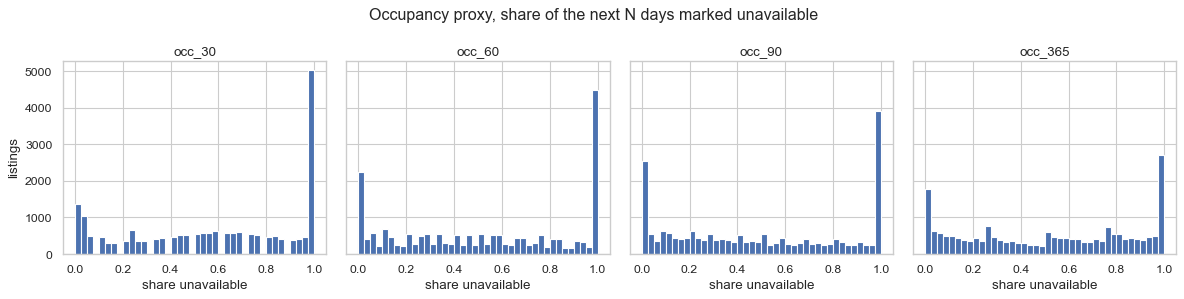

In [3]:
OCCUPANCY_WINDOWS = (30, 60, 90, 365)

occupancy = pd.DataFrame(index=pd.Index(sorted(calendar["listing_id"].unique()),
                                       name="listing_id"))
for window in OCCUPANCY_WINDOWS:
    in_window = calendar["day_offset"] < window
    occupancy[f"occ_{window}"] = (
        calendar.loc[in_window].groupby("listing_id")["unavailable"].mean()
    )

print("occupancy proxy distributions (share of days unavailable)")
print(occupancy.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(4).to_string())

print("\ncross-file check against the listings availability_N columns")
check = listings.set_index("id")[[f"availability_{w}" for w in OCCUPANCY_WINDOWS]]
for window in OCCUPANCY_WINDOWS:
    expected = 1 - check[f"availability_{window}"] / window
    both = occupancy[f"occ_{window}"].reindex(check.index)
    difference = (both - expected).abs()
    print(f"  occ_{window:<3} vs 1 - availability_{window}/{window}: "
          f"max abs diff={difference.max():.6f}  "
          f"mean abs diff={difference.mean():.6f}  "
          f"exact matches={np.isclose(both, expected).mean():.2%}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for axis, window in zip(axes, OCCUPANCY_WINDOWS):
    axis.hist(occupancy[f"occ_{window}"].dropna(), bins=40, color="#4C72B0")
    axis.set_title(f"occ_{window}")
    axis.set_xlabel("share unavailable")
axes[0].set_ylabel("listings")
fig.suptitle("Occupancy proxy, share of the next N days marked unavailable")
fig.tight_layout()
save_figure(fig, "occupancy_proxy_distributions")
plt.show()

## 3. Weekend against weekday

If unavailability tracked real demand it should lean towards weekends, because
leisure demand does. If it is mostly hosts blocking long stretches, the two
shares should look alike. The difference is therefore a cheap test of how much
demand signal the proxy carries, and it is a feature worth building either way.

Weekend means Saturday or Sunday.

weekend listing-days : 2,166,632
weekday listing-days : 5,437,413

pooled share unavailable, weekend : 0.5264
pooled share unavailable, weekday : 0.5182
pooled difference                 : +0.0082

per-listing distributions
       weekend_occ_365  weekday_occ_365  weekend_minus_weekday_occ
count       20833.0000       20833.0000                 20833.0000
mean            0.5264           0.5182                     0.0082
std             0.3406           0.3435                     0.0289
min             0.0000           0.0000                    -0.5321
10%             0.0481           0.0345                    -0.0156
50%             0.5481           0.5402                     0.0003
90%             1.0000           1.0000                     0.0425
max             1.0000           1.0000                     0.5172

listings more blocked at weekends : 10,659 (51.16%)
listings with no difference       : 2,825 (13.56%)


saved reports/figures/weekend_vs_weekday_occupancy.png


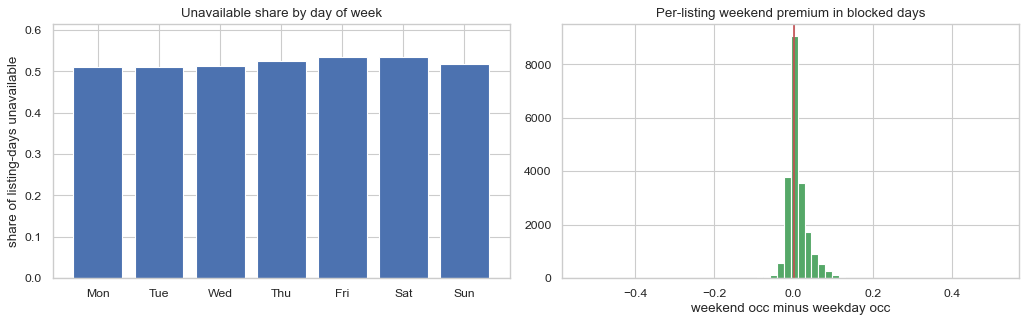

In [4]:
calendar["is_weekend"] = calendar["date"].dt.dayofweek >= 5

weekend_frame = calendar.loc[calendar["is_weekend"]]
weekday_frame = calendar.loc[~calendar["is_weekend"]]

occupancy["weekend_occ_365"] = weekend_frame.groupby("listing_id")["unavailable"].mean()
occupancy["weekday_occ_365"] = weekday_frame.groupby("listing_id")["unavailable"].mean()
occupancy["weekend_minus_weekday_occ"] = (
    occupancy["weekend_occ_365"] - occupancy["weekday_occ_365"]
)

print(f"weekend listing-days : {len(weekend_frame):,}")
print(f"weekday listing-days : {len(weekday_frame):,}")
print(f"\npooled share unavailable, weekend : "
      f"{weekend_frame['unavailable'].mean():.4f}")
print(f"pooled share unavailable, weekday : "
      f"{weekday_frame['unavailable'].mean():.4f}")
print(f"pooled difference                 : "
      f"{weekend_frame['unavailable'].mean() - weekday_frame['unavailable'].mean():+.4f}")

print("\nper-listing distributions")
print(
    occupancy[["weekend_occ_365", "weekday_occ_365", "weekend_minus_weekday_occ"]]
    .describe(percentiles=[0.1, 0.5, 0.9])
    .round(4)
    .to_string()
)
print(f"\nlistings more blocked at weekends : "
      f"{int((occupancy['weekend_minus_weekday_occ'] > 0).sum()):,} "
      f"({(occupancy['weekend_minus_weekday_occ'] > 0).mean():.2%})")
print(f"listings with no difference       : "
      f"{int((occupancy['weekend_minus_weekday_occ'] == 0).sum()):,} "
      f"({(occupancy['weekend_minus_weekday_occ'] == 0).mean():.2%})")

by_dayofweek = calendar.groupby(calendar["date"].dt.dayofweek)["unavailable"].mean()
by_dayofweek.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(by_dayofweek.index, by_dayofweek.to_numpy(), color="#4C72B0")
axes[0].set_ylabel("share of listing-days unavailable")
axes[0].set_title("Unavailable share by day of week")
axes[0].set_ylim(0, max(0.6, by_dayofweek.max() * 1.15))
axes[1].hist(occupancy["weekend_minus_weekday_occ"].dropna(), bins=60, color="#55A868")
axes[1].axvline(0, color="#C44E52", lw=1.5)
axes[1].set_xlabel("weekend occ minus weekday occ")
axes[1].set_title("Per-listing weekend premium in blocked days")
fig.tight_layout()
save_figure(fig, "weekend_vs_weekday_occupancy")
plt.show()

## 4. Dormant and fully open listings

Two groups need naming before any demand feature is trusted.

- **Blocked all year**: `occ_365 == 1`. No bookable day exists, so the listing
  is almost certainly dormant rather than fully booked. These rows look like
  maximum demand to a naive model.
- **Open all year**: `occ_365 == 0`. Either brand new, or never booked.

`n_availability_blocks_365` counts separate runs of unavailable dates. One long
run reads like a host closing the calendar; many short runs read like
individual bookings. It is the one feature here that distinguishes the two
stories.

blocked all year (occ_365 == 1) : 2,238 (10.74%)
open all year (occ_365 == 0)    : 587 (2.82%)

n_availability_blocks_365
count    20833.00
mean         5.44
std          5.42
min          0.00
10%          1.00
50%          4.00
90%         13.00
99%         24.00
max         74.00

blocks against occupancy, to separate dormant from booked
                   listings  median_blocks  mean_blocks
occ_365                                                
0 (fully open)          587            0.0         0.00
0 to 0.25              5341            4.0         5.58
0.25 to 0.5            3581            6.0         7.67
0.5 to 0.75            4178            5.0         6.80
0.75 to <1             4908            4.0         5.16
1 (fully blocked)      2238            1.0         1.00


saved reports/figures/availability_blocks.png


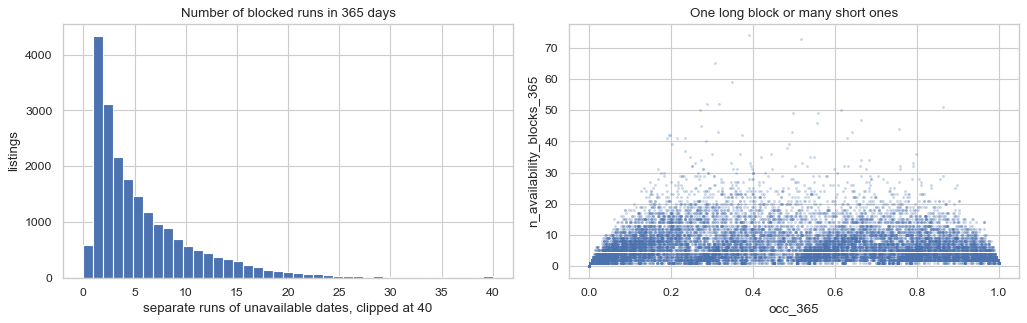

In [5]:
# Runs of unavailable dates. The frame is checked for (listing_id, date) order
# first, because run counting depends on it.
ordered = calendar.sort_values(["listing_id", "day_offset"], kind="stable")
listing_ids = ordered["listing_id"].to_numpy()
unavailable = ordered["unavailable"].to_numpy()

previous_unavailable = np.concatenate(([False], unavailable[:-1]))
same_listing = np.concatenate(([False], listing_ids[1:] == listing_ids[:-1]))
is_block_start = unavailable & ~(previous_unavailable & same_listing)

occupancy["n_availability_blocks_365"] = (
    pd.Series(is_block_start, index=ordered["listing_id"]).groupby(level=0).sum()
)
occupancy["blocked_all_year"] = (occupancy["occ_365"] >= 1.0).astype("int8")

print(f"blocked all year (occ_365 == 1) : "
      f"{int(occupancy['blocked_all_year'].sum()):,} "
      f"({occupancy['blocked_all_year'].mean():.2%})")
print(f"open all year (occ_365 == 0)    : "
      f"{int((occupancy['occ_365'] <= 0).sum()):,} "
      f"({(occupancy['occ_365'] <= 0).mean():.2%})")

print("\nn_availability_blocks_365")
print(occupancy["n_availability_blocks_365"].describe(
    percentiles=[0.1, 0.5, 0.9, 0.99]
).round(2).to_string())

print("\nblocks against occupancy, to separate dormant from booked")
bands = pd.cut(occupancy["occ_365"], [-0.001, 0.0, 0.25, 0.5, 0.75, 0.999, 1.0],
               labels=["0 (fully open)", "0 to 0.25", "0.25 to 0.5",
                       "0.5 to 0.75", "0.75 to <1", "1 (fully blocked)"])
print(
    occupancy.groupby(bands, observed=False)
    .agg(listings=("occ_365", "size"),
         median_blocks=("n_availability_blocks_365", "median"),
         mean_blocks=("n_availability_blocks_365", "mean"))
    .round(2)
    .to_string()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(occupancy["n_availability_blocks_365"].clip(upper=40), bins=41,
             color="#4C72B0")
axes[0].set_xlabel("separate runs of unavailable dates, clipped at 40")
axes[0].set_ylabel("listings")
axes[0].set_title("Number of blocked runs in 365 days")
axes[1].scatter(occupancy["occ_365"], occupancy["n_availability_blocks_365"],
                s=3, alpha=0.2, color="#4C72B0", rasterized=True)
axes[1].set_xlabel("occ_365")
axes[1].set_ylabel("n_availability_blocks_365")
axes[1].set_title("One long block or many short ones")
fig.tight_layout()
save_figure(fig, "availability_blocks")
plt.show()

## 5. Reviews over time and per listing

Only `listing_id` and `date` are read. The review text stays on disk.

A review is a booking that happened and was reviewed, so review counts are a
**lower bound** on bookings with an unknown and probably drifting response
rate. They are still the only record of realised demand in this dataset.

review rows        : 829,163
unique listings    : 17,623
date range         : 2009-12-05 to 2026-09-17
reviews after the snapshot date: 0
columns held       : ['listing_id', 'date']  (no text loaded)


saved reports/figures/reviews_over_time_and_per_listing.png


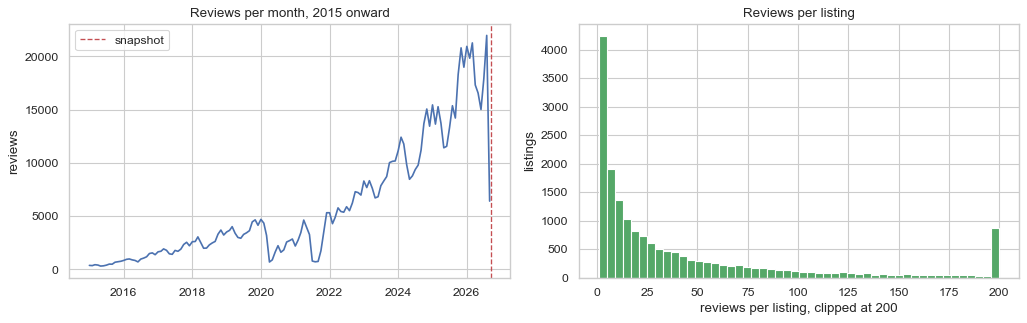


reviews per listing (listings that have at least one)
count    17623.00
mean        47.05
std         79.24
min          1.00
10%          2.00
50%         18.00
90%        124.00
99%        391.00
max       1166.00

listings with at least one review : 17,623 (84.59%)
listings with no reviews at all   : 3,210 (15.41%)

the 12 months before the snapshot held 221,769 reviews


In [6]:
reviews = pd.read_csv(
    resolve_raw("reviews"),
    usecols=["listing_id", "date"],
    dtype={"listing_id": "int64"},
    parse_dates=["date"],
)
assert set(reviews.columns) == {"listing_id", "date"}, "unexpected review columns read"

print(f"review rows        : {len(reviews):,}")
print(f"unique listings    : {reviews['listing_id'].nunique():,}")
print(f"date range         : {reviews['date'].min().date()} to "
      f"{reviews['date'].max().date()}")
print(f"reviews after the snapshot date: "
      f"{int((reviews['date'] > SNAPSHOT_DATE).sum()):,}")
print(f"columns held       : {list(reviews.columns)}  (no text loaded)")

per_month = reviews.set_index("date").resample("MS").size()
recent = per_month.loc[per_month.index >= "2015-01-01"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(recent.index, recent.to_numpy(), color="#4C72B0")
axes[0].set_title("Reviews per month, 2015 onward")
axes[0].set_ylabel("reviews")
axes[0].axvline(SNAPSHOT_DATE, color="#C44E52", lw=1.2, ls="--", label="snapshot")
axes[0].legend()

per_listing = reviews.groupby("listing_id").size()
axes[1].hist(per_listing.clip(upper=200), bins=50, color="#55A868")
axes[1].set_xlabel("reviews per listing, clipped at 200")
axes[1].set_ylabel("listings")
axes[1].set_title("Reviews per listing")
fig.tight_layout()
save_figure(fig, "reviews_over_time_and_per_listing")
plt.show()

print("\nreviews per listing (listings that have at least one)")
print(per_listing.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(2).to_string())

listings_with_reviews = int(listings["id"].isin(reviews["listing_id"]).sum())
print(f"\nlistings with at least one review : {listings_with_reviews:,} "
      f"({listings_with_reviews / len(listings):.2%})")
print(f"listings with no reviews at all   : "
      f"{len(listings) - listings_with_reviews:,} "
      f"({1 - listings_with_reviews / len(listings):.2%})")
print(f"\nthe 12 months before the snapshot held "
      f"{int((reviews['date'] > SNAPSHOT_DATE - pd.Timedelta(days=365)).sum()):,} "
      f"reviews")

## 6. Review recency at the snapshot date

`days_since_last_review` is measured from the snapshot date, so it is stable
no matter when the notebook is rerun. A large value on a listing with many
reviews is the signature of a listing that has gone quiet, which is a
different state from never having been reviewed.

`review_growth` compares the last 365 days with the 365 before that. A plain
ratio is undefined when the earlier year is zero, which is the common case for
a newer listing, so the ratio is smoothed by adding one to each side:
`(reviews_last_365d + 1) / (reviews_365_to_730d + 1)`. That is defined
everywhere, equals 1 when both years are empty, and needs no fitted statistic.

review aggregates, over the listings that have at least one review
       reviews_last_90d  reviews_last_180d  reviews_last_365d  reviews_365_to_730d  days_since_last_review  first_review_age_years  review_growth
count         17623.000          17623.000          17623.000            17623.000               17623.000               17623.000      17623.000
mean              2.944              5.777             12.584                9.357                 239.851                   3.115          4.309
std               4.447              8.184             15.817               15.192                 527.606                   3.110          8.504
min               0.000              0.000              0.000                0.000                   0.000                   0.000          0.014
10%               0.000              0.000              0.000                0.000                   7.000                   0.298          0.500
50%               1.000              3.000              7

growth above 1 (speeding up)  : 57.49%
growth below 1 (slowing down) : 30.04%


saved reports/figures/review_recency_and_growth.png


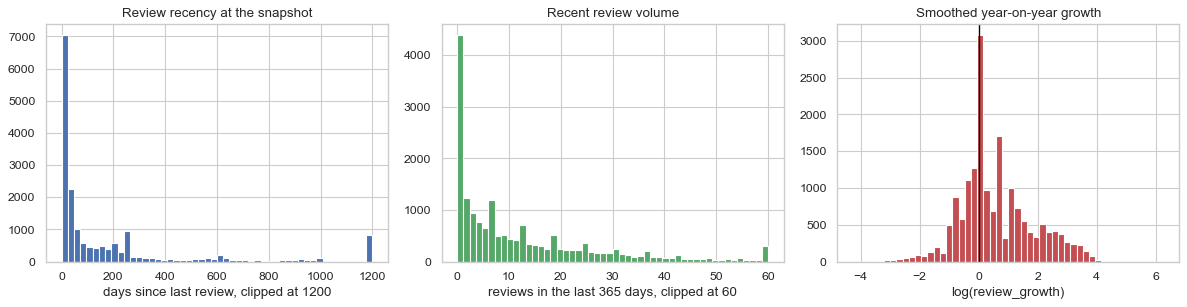

In [7]:
reviews["days_ago"] = (SNAPSHOT_DATE - reviews["date"]).dt.days

review_aggregates = pd.DataFrame(
    index=pd.Index(sorted(reviews["listing_id"].unique()), name="listing_id")
)
for window in (90, 180, 365):
    counts = (
        reviews.loc[reviews["days_ago"].between(0, window - 1)]
        .groupby("listing_id")
        .size()
    )
    review_aggregates[f"reviews_last_{window}d"] = counts

prior_year = (
    reviews.loc[reviews["days_ago"].between(365, 729)].groupby("listing_id").size()
)
review_aggregates["reviews_365_to_730d"] = prior_year
review_aggregates = review_aggregates.fillna(0)

review_aggregates["days_since_last_review"] = (
    reviews.groupby("listing_id")["days_ago"].min()
)
review_aggregates["first_review_age_years"] = (
    reviews.groupby("listing_id")["days_ago"].max() / 365.25
)
review_aggregates["review_growth"] = (
    review_aggregates["reviews_last_365d"] + 1
) / (review_aggregates["reviews_365_to_730d"] + 1)

print("review aggregates, over the listings that have at least one review")
print(
    review_aggregates.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(3).to_string()
)

print(f"\nlistings quiet for over a year : "
      f"{int((review_aggregates['days_since_last_review'] > 365).sum()):,} "
      f"({(review_aggregates['days_since_last_review'] > 365).mean():.2%} "
      f"of reviewed listings)")
print(f"listings reviewed in the last 30 days : "
      f"{int((review_aggregates['days_since_last_review'] <= 30).sum()):,}")
print(f"growth above 1 (speeding up)  : "
      f"{(review_aggregates['review_growth'] > 1).mean():.2%}")
print(f"growth below 1 (slowing down) : "
      f"{(review_aggregates['review_growth'] < 1).mean():.2%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
axes[0].hist(review_aggregates["days_since_last_review"].clip(upper=1200), bins=50,
             color="#4C72B0")
axes[0].set_xlabel("days since last review, clipped at 1200")
axes[0].set_title("Review recency at the snapshot")
axes[1].hist(review_aggregates["reviews_last_365d"].clip(upper=60), bins=50,
             color="#55A868")
axes[1].set_xlabel("reviews in the last 365 days, clipped at 60")
axes[1].set_title("Recent review volume")
axes[2].hist(np.log(review_aggregates["review_growth"]), bins=50, color="#C44E52")
axes[2].axvline(0, color="black", lw=1.2)
axes[2].set_xlabel("log(review_growth)")
axes[2].set_title("Smoothed year-on-year growth")
fig.tight_layout()
save_figure(fig, "review_recency_and_growth")
plt.show()

## 7. Relationship checks against log price

The question is whether these aggregates carry any price signal at all. If
they do not, the hypothesis is in trouble on this dataset and the write-up
should say so rather than lean on them.

Spearman, on priced listings only.

priced listings joined: 17,721
  with calendar rows : 17,721
  with review rows   : 15,146

Spearman correlation with log1p(price)
occ_30                       0.1361
n_availability_blocks_365    0.1306
occ_60                       0.1244
occ_90                       0.1188
reviews_last_180d           -0.0522
weekend_minus_weekday_occ    0.0495
first_review_age_years      -0.0415
reviews_last_365d           -0.0399
weekend_occ_365              0.0368
reviews_last_90d            -0.0366
occ_365                      0.0351
weekday_occ_365              0.0343
days_since_last_review       0.0307
review_growth                0.0015

columns that are CONSTANT over the priced rows, so correlation is undefined:
  blocked_all_year: single value [0]

  all-listings picture for comparison:
    blocked all year, all 20,833 listings : 2,238
    blocked all year, priced listings only            : 0
  -> every fully blocked listing is also unpriced, so the flag carries no signal once the
     master 

saved reports/figures/demand_proxies_vs_log_price.png


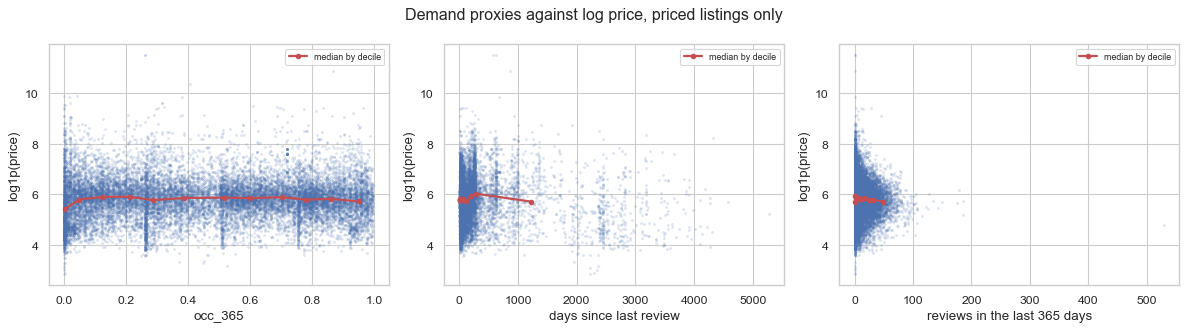


median price (AUD) by occ_365 band
                  n  median
occ_365                    
(-0.001, 0.0]   532  182.82
(0.0, 0.25]    5198  345.30
(0.25, 0.5]    3477  338.00
(0.5, 0.75]    4082  354.50
(0.75, 0.999]  4432  325.00
(0.999, 1.0]      0     NaN


In [8]:
merged = (
    listings.loc[listings["price_num"] > 0, ["id", "log_price", "price_num", "room_type"]]
    .merge(occupancy, left_on="id", right_index=True, how="left")
    .merge(review_aggregates, left_on="id", right_index=True, how="left")
)
print(f"priced listings joined: {len(merged):,}")
print(f"  with calendar rows : {merged['occ_365'].notna().sum():,}")
print(f"  with review rows   : {merged['reviews_last_365d'].notna().sum():,}")

AGGREGATE_COLUMNS = [
    "occ_30", "occ_60", "occ_90", "occ_365",
    "weekend_occ_365", "weekday_occ_365", "weekend_minus_weekday_occ",
    "n_availability_blocks_365", "blocked_all_year",
    "reviews_last_90d", "reviews_last_180d", "reviews_last_365d",
    "days_since_last_review", "review_growth", "first_review_age_years",
]
aggregate_frame = merged[AGGREGATE_COLUMNS].apply(pd.to_numeric, errors="coerce")

# A rank correlation is undefined for a column that does not vary, so those are
# separated out and reported on their own rather than shown as a NaN. That a
# column is constant here is a finding about the data, not a failed calculation.
variation = aggregate_frame.nunique(dropna=True)
constant_on_priced = variation.index[variation <= 1].tolist()
varying_columns = [c for c in AGGREGATE_COLUMNS if c not in constant_on_priced]

correlations = (
    aggregate_frame[varying_columns]
    .corrwith(merged["log_price"], method="spearman")
    .sort_values(key=np.abs, ascending=False)
    .round(4)
)
print("\nSpearman correlation with log1p(price)")
print(correlations.to_string())

if constant_on_priced:
    print("\ncolumns that are CONSTANT over the priced rows, so correlation is "
          "undefined:")
    for column in constant_on_priced:
        only_value = merged[column].dropna().unique()
        print(f"  {column}: single value {only_value}")
    print("\n  all-listings picture for comparison:")
    print(f"    blocked all year, all {len(occupancy):,} listings : "
          f"{int(occupancy['blocked_all_year'].sum()):,}")
    print(f"    blocked all year, priced listings only            : "
          f"{int(merged['blocked_all_year'].sum()):,}")
    print("  -> every fully blocked listing is also unpriced, so the flag "
          "carries no signal once the")
    print("     master dataset is restricted to priced rows. Kept as a column "
          "for provenance, but it")
    print("     cannot be a feature on this snapshot.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for axis, column, label in zip(
    axes,
    ["occ_365", "days_since_last_review", "reviews_last_365d"],
    ["occ_365", "days since last review", "reviews in the last 365 days"],
):
    frame = merged.loc[merged[column].notna()]
    bins = pd.qcut(frame[column].rank(method="first"), 12, duplicates="drop")
    grouped = frame.groupby(bins, observed=False).agg(
        x=(column, "median"), y=("log_price", "median")
    )
    axis.scatter(frame[column], frame["log_price"], s=3, alpha=0.12,
                 color="#4C72B0", rasterized=True)
    axis.plot(grouped["x"], grouped["y"], color="#C44E52", lw=2,
              marker="o", ms=4, label="median by decile")
    axis.set_xlabel(label)
    axis.set_ylabel("log1p(price)")
    axis.legend(fontsize=8)
fig.suptitle("Demand proxies against log price, priced listings only")
fig.tight_layout()
save_figure(fig, "demand_proxies_vs_log_price")
plt.show()

print("\nmedian price (AUD) by occ_365 band")
print(
    merged.groupby(
        pd.cut(merged["occ_365"], [-0.001, 0.0, 0.25, 0.5, 0.75, 0.999, 1.0]),
        observed=False,
    )["price_num"]
    .agg(n="size", median="median")
    .round(2)
    .to_string()
)

## 8. Recomputed review counts against the listings column

`number_of_reviews` in the listings table should equal the number of rows in
`reviews.csv` for that listing. Where it does not, one of the two files is
incomplete, and the mismatch pattern says which.

In [9]:
recomputed = reviews.groupby("listing_id").size().rename("recomputed_reviews")
comparison = (
    listings.set_index("id")[["number_of_reviews", "number_of_reviews_ltm"]]
    .join(recomputed, how="left")
    .join(review_aggregates["reviews_last_365d"], how="left")
)
comparison["recomputed_reviews"] = comparison["recomputed_reviews"].fillna(0)
comparison["reviews_last_365d"] = comparison["reviews_last_365d"].fillna(0)
comparison["difference"] = (
    comparison["number_of_reviews"] - comparison["recomputed_reviews"]
)
comparison["ltm_difference"] = (
    comparison["number_of_reviews_ltm"] - comparison["reviews_last_365d"]
)

matches = int((comparison["difference"] == 0).sum())
print("all-time counts: listings column vs rows in reviews.csv")
print(f"  exact matches   : {matches:,} ({matches / len(comparison):.2%})")
print(f"  mismatches      : {len(comparison) - matches:,}")
print(f"  listings higher : {int((comparison['difference'] > 0).sum()):,}")
print(f"  reviews higher  : {int((comparison['difference'] < 0).sum()):,}")
print("\n  difference distribution (listings minus recomputed)")
print(comparison["difference"].describe(
    percentiles=[0.01, 0.5, 0.99]
).round(2).to_string())

ltm_matches = int((comparison["ltm_difference"] == 0).sum())
print("\nlast-12-months counts: number_of_reviews_ltm vs reviews_last_365d")
print(f"  exact matches : {ltm_matches:,} ({ltm_matches / len(comparison):.2%})")
print("  difference distribution")
print(comparison["ltm_difference"].describe(
    percentiles=[0.01, 0.5, 0.99]
).round(2).to_string())

print("\nworst 10 all-time mismatches")
print(
    comparison.reindex(comparison["difference"].abs().sort_values(ascending=False).index)
    .head(10)[["number_of_reviews", "recomputed_reviews", "difference"]]
    .to_string()
)

all-time counts: listings column vs rows in reviews.csv
  exact matches   : 20,833 (100.00%)
  mismatches      : 0
  listings higher : 0
  reviews higher  : 0

  difference distribution (listings minus recomputed)
count    20833.0
mean         0.0
std          0.0
min          0.0
1%           0.0
50%          0.0
99%          0.0
max          0.0

last-12-months counts: number_of_reviews_ltm vs reviews_last_365d
  exact matches : 20,552 (98.65%)
  difference distribution
count    20833.00
mean         0.01
std          0.12
min          0.00
1%           0.00
50%          0.00
99%          1.00
max          2.00

worst 10 all-time mismatches
                     number_of_reviews  recomputed_reviews  difference
id                                                                    
1731699709801482872                  0                 0.0         0.0
1731206301472000721                  6                 6.0         0.0
1731169736182209266                  1                 1.0       

## 9. What these proxies can and cannot mean

This section exists so the limitation is stated once, in the project's own
words, rather than being discovered by a reader of Chapter 5.

**Unavailable does not mean booked.** The calendar records one bit per listing
per day. A day marked unavailable can be a confirmed booking, a date the host
blocked for their own use, a date closed because the minimum stay cannot fit,
or a listing that has been left dormant with the calendar shut. Inside Airbnb
publishes no booking flag, so the four cases are indistinguishable here. Every
`occ_*` figure is therefore an **upper bound** on occupancy, not a measurement
of it.

Two consequences worth stating plainly:

- `blocked_all_year` almost certainly marks dormant listings, not perfectly
  booked ones. Treating `occ_365 == 1` as maximum demand would invert the
  meaning, which is why the flag exists as its own column.
- `n_availability_blocks_365` is the only column that separates the stories.
  One long run is consistent with a closed calendar; many short runs are
  consistent with individual bookings. Neither is proof.

**Reviews are a lower bound on bookings.** A review requires a completed stay
*and* a guest who chose to write one. The response rate is unknown and drifts
over time and across listing types, so review counts understate bookings by an
unknown factor. Review-based demand features measure *reviewed* demand.

**What transfers to the mentorship platform.** The structural claim is only
that provider attributes plus performance plus demand map to price. On the real
platform the demand side will be measured directly as profile views and
booking requests, which have none of these ambiguities. The proxies here stand
in for the *shape* of that signal, so a weak result on this dataset is weak
evidence about Airbnb calendars, not a refutation of the hypothesis on
platform data.

**What is not claimed.** Nothing here says accommodation and mentorship
pricing behave alike, that Sydney price levels transfer, or that the size of
any effect measured here will carry over.

In [10]:
print("summary of what notebook 03 will build from these two files\n")
summary = pd.Series(
    {
        "snapshot date": str(SNAPSHOT_DATE.date()),
        "calendar listing-days read": f"{len(calendar):,}",
        "calendar listings": f"{calendar['listing_id'].nunique():,}",
        "calendar days per listing": int(rows_per_listing.iloc[0]),
        "review rows read": f"{len(reviews):,}",
        "review listings": f"{reviews['listing_id'].nunique():,}",
        "calendar aggregates": len([c for c in AGGREGATE_COLUMNS if c.startswith(
            ("occ", "weekend", "weekday", "n_avail", "blocked"))]),
        "review aggregates": len([c for c in AGGREGATE_COLUMNS if c.startswith(
            ("reviews_", "days_since", "review_growth", "first_review"))]),
        "strongest proxy correlation": (
            f"{correlations.index[0]} at {correlations.iloc[0]:+.4f}"
        ),
        "weakest defined correlation": (
            f"{correlations.index[-1]} at {correlations.iloc[-1]:+.4f}"
        ),
        "constant over priced rows": ", ".join(constant_on_priced) or "none",
    }
)
print(summary.to_string())

print("\nfigures in reports/figures/ after this notebook:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(f"  {path.name}  ({path.stat().st_size / 1024:.0f} KB)")

summary of what notebook 03 will build from these two files

snapshot date                                2026-09-17
calendar listing-days read                    7,604,045
calendar listings                                20,833
calendar days per listing                           365
review rows read                                829,163
review listings                                  17,623
calendar aggregates                                   9
review aggregates                                     6
strongest proxy correlation           occ_30 at +0.1361
weakest defined correlation    review_growth at +0.0015
constant over priced rows              blocked_all_year

figures in reports/figures/ after this notebook:
  availability_blocks.png  (190 KB)
  demand_proxies_vs_log_price.png  (331 KB)
  geography_and_cbd_distance.png  (499 KB)
  median_price_by_neighbourhood.png  (109 KB)
  numeric_correlation_heatmap.png  (183 KB)
  numeric_distributions.png  (122 KB)
  occupancy_proxy_dist